In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw5.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 5: Airbnb regression 
### Associated lectures: All material till lecture 13 

<div class="alert alert-info">

## Instructions
rubric={points}

You will earn points for following these instructions and successfully submitting your work in PrairieLearn.

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.

- The maximum group size is 2.
- Use group work as an opportunity to collaborate and learn new things from each other.
- Be respectful to each other and make sure you understand all the concepts in the assignment well.
- It is your responsibility to make sure your PrairieLearn group is set up correctly and that the assignment is submitted before the deadline.

### General submission instructions

- Please read the [Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2026S1/syllabus#use-of-generative-ai-in-the-course) before starting the homework assignment.
- **Run all cells before submitting:** Go to `Kernel -> Restart Kernel and Clear All Outputs`, then select `Run -> Run All Cells`. This ensures your notebook runs cleanly from start to finish without errors.
- **Save your work in JupyterLab:** Make sure `hw5.ipynb` is saved.
- **Choose one HW5 option:** HW5 has two dataset options in PrairieLearn. You are currently in the Airbnb regression option. Open and submit exactly one notebook, and do not submit both.
- **Check your saved submission in PrairieLearn:** Return to the PrairieLearn question page and click **Save only** to capture your notebook and review the preview. When you are ready to submit for grading, click **Save & Grade**.
- **Follow course submission guidelines:** Review the [CPSC 330 homework instructions](https://ubc-cs.github.io/cpsc330-2026S1/docs/homework-instructions/) for detailed guidance on completing and submitting assignments.

</div>


_Note: Unlike previous assignments, this one is open-ended and project-style. Treat it as an opportunity to explore, experiment, and learn._

<!-- BEGIN QUESTION -->

## Imports

<div class="alert alert-warning">
    
Imports
    
</div>

_Points:_ 0

In [2]:
import pandas as pd
import os
import sys
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFECV

<!-- END QUESTION -->

## Introduction

In this homework you will be working on an open-ended mini-project, where you will put all the different things you have learned so far together to solve an interesting problem.

A few notes and tips when you work on this mini-project: 

#### Tips
1. This mini-project is open-ended, and while working on it, there might be some situations where you'll have to use your own judgment and make your own decisions (as you would be doing when you work as a data scientist). Make sure you explain your decisions whenever necessary. 
2. **Do not include everything you ever tried in your submission** -- it's fine just to have your final code. That said, your code should be reproducible and well-documented. For example, if you chose your hyperparameters based on some hyperparameter optimization experiment, you should leave in the code for that experiment so that someone else could re-run it and obtain the same hyperparameters, rather than mysteriously just setting the hyperparameters to some (carefully chosen) values in your code. 
3. If you realize that you are repeating a lot of code try to organize it in functions. Clear presentation of your code, experiments, and results is the key to be successful in this lab. You may use code from lecture notes or previous lab solutions with appropriate attributions. 

#### Assessment
We plan to grade fairly and leniently. We don't have some secret target score that you need to achieve to get a good grade. **You'll be assessed on demonstration of mastery of course topics, clear presentation, and the quality of your analysis and results.** For example, if you just have a bunch of code and no text or figures, that's not good. If you do a bunch of sane things and get a lower accuracy than your friend, don't sweat it.


#### A final note
Finally, this style of this "project" question is different from other assignments. It'll be up to you to decide when you're "done" -- in fact, this is one of the hardest parts of real projects. But please don't spend WAY too much time on this... perhaps "a few hours" (10-14 hours???) is a good guideline for this project . Of course if you're having fun you're welcome to spend as much time as you want! But, if so, try not to do it out of perfectionism or getting the best possible grade. Do it because you're learning and enjoying it. Students from the past cohorts have found such kind of labs useful and fun and I hope you enjoy it as well. 

<br><br>

<!-- BEGIN QUESTION -->

## 1. Pick your problem and explain the prediction problem
<hr>
rubric={points:3}

This version of Homework 5 uses the [New York City Airbnb Open Data dataset](https://www.kaggle.com/dgomonov/new-york-city-airbnb-open-data). You will work on a regression problem where the goal is to predict `reviews_per_month`, as a proxy for listing popularity. Airbnb could use this sort of model to predict how popular future listings might be before they are posted, perhaps to help guide hosts in creating more appealing listings. In reality they might instead use something like vacancy rate or average rating as their target, but we do not have that available here.

> Note there is an updated version of this dataset with more features available [here](http://insideairbnb.com/). The features we are using are in `listings.csv.gz` for the New York City dataset. You will also see some other files like `reviews.csv.gz`. For your own interest you may want to explore the expanded dataset and try your analysis there. However, please submit your results on the dataset obtained from Kaggle.

<div class="alert alert-info">
    
**Your tasks:**

1. Spend some time understanding the problem and what each feature means. You can find an explanation of the features [here](https://docs.google.com/spreadsheets/d/1iWCNJcSutYqpULSQHlNyGInUvHg2BoUGoNRIGa6Szc4/edit).
2. Download the dataset and load it into a pandas DataFrame.
3. Write a few sentences summarizing your initial thoughts about the problem and the dataset.
   
</div>


<div class="alert alert-warning">
    
Solution_1
    
</div>

_Points:_ 3

The dataset contains 48895 airbnb's. This is a regression based problem because the target feature reviews_per_month is numerical. One thing that really stands out in intial inspection of the dataset is that there are 10052 mising values in the tagrte feature meaning 20.5% of the rows are missing the target feature value. This means later on in this investigation, I would have to impute these values. The mean price after applying, describe() seems to be $153 but the maximum being $10,000 and the median is $106 which is much lower than mean indicating that the data is rightly skewed. The maximum reviews per month is 58.5, which is much larger than the median (0.72), again suggesting skewness and potential outliers. There are 5 neighbourhood groups, suggested by "unique:5", Manhattan is the most common with 21661 houses. The most common house type is "Entire home/apt" with 25,409 lisstings. The feature I am likely to drop during preprocessing are id, host_id, name and host_name, these are identifiers rather than meaningful characteristics. 

In [7]:
df = pd.read_csv("AB_NYC_2019.csv")
print(df.shape)
df.head()
df.info()
print(df.describe(include="all"))
df.isnull().sum().sort_values(ascending=False)

(48895, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review         

last_review                       10052
reviews_per_month                 10052
host_name                            21
name                                 16
id                                    0
host_id                               0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 2. Data splitting
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. Split the data into train (70%) and test (30%) portions with `random_state=123`.

> If your computer cannot handle training on 70% training data, make the test split bigger.

</div>

<div class="alert alert-warning">
    
Solution_2
    
</div>

_Points:_ 2

In [8]:
df = df.dropna(subset=["reviews_per_month"])
train_df, test_df = train_test_split(
    df,
    test_size=0.3,
    random_state=123
)

X_train = train_df.drop(columns=["reviews_per_month"])
y_train = train_df["reviews_per_month"]

X_test = test_df.drop(columns=["reviews_per_month"])
y_test = test_df["reviews_per_month"]

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 3. EDA
<hr>
rubric={points:10}

<div class="alert alert-info">

**Your tasks:**

1. **Perform exploratory data analysis (EDA)**: Conduct an initial exploration of the training set to better understand its characteristics.

2. **Summarize and visualize the data**: Include at least **two summary statistics** and **two visualizations** that you find informative. For each, write **one sentence** explaining what insight it provides.

3. **Record your observations**: Summarize your **initial observations** about the dataset based on your EDA.

4. **Select evaluation metrics**: Choose one or more **appropriate metrics** for assessing model performance and briefly justify your choice.

</div>

<div class="alert alert-warning">
    
Solution_3
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [9]:
train_df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,2.719000e+04,2.719000e+04,27190.000000,27190.000000,27190.000000,27190.000000,27190.000000,27190.000000,27190.000000,27190.000000
mean,1.797184e+07,6.362771e+07,40.728298,-73.951300,142.948216,5.865576,29.613829,1.365532,5.143104,115.335086
std,1.071079e+07,7.549422e+07,0.055004,0.046682,208.069211,17.122889,48.895629,1.642444,25.967484,129.752309
min,2.539000e+03,2.787000e+03,40.506410,-74.244420,0.000000,1.000000,1.000000,0.010000,1.000000,0.000000
25%,8.550050e+06,6.959995e+06,40.688763,-73.982530,69.000000,1.000000,3.000000,0.190000,1.000000,0.000000
50%,1.871866e+07,2.767398e+07,40.721710,-73.954825,104.000000,2.000000,9.000000,0.720000,1.000000,56.000000
75%,2.748837e+07,1.009713e+08,40.763000,-73.935245,170.000000,4.000000,33.000000,2.000000,2.000000,231.000000
max,3.645581e+07,2.738417e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,19.750000,327.000000,365.000000


As seen from the summary statistics, the numerical features are on very different scales. For example, price ranges from 0 to 10,000 dollars, while latitude only ranges from approximately 40.5 to 40.9. Similarly, minimum_nights ranges from 1 to 1250 and number_of_reviews ranges from 0 to 629. Because the features have very different ranges and magnitudes, scaling may be useful for some machine learning models during preprocessing. 

In [10]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 27190 entries, 14989 to 18940
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              27190 non-null  int64  
 1   name                            27186 non-null  object 
 2   host_id                         27190 non-null  int64  
 3   host_name                       27177 non-null  object 
 4   neighbourhood_group             27190 non-null  object 
 5   neighbourhood                   27190 non-null  object 
 6   latitude                        27190 non-null  float64
 7   longitude                       27190 non-null  float64
 8   room_type                       27190 non-null  object 
 9   price                           27190 non-null  int64  
 10  minimum_nights                  27190 non-null  int64  
 11  number_of_reviews               27190 non-null  int64  
 12  last_review                     2

as we can see after calling info() the last_review and reviews_per_month have the same number of non null observations suggesting that the missing values occur in the same listing. This may indicate that listings with no recorded reviews are missing both the review date and the review frequency information.

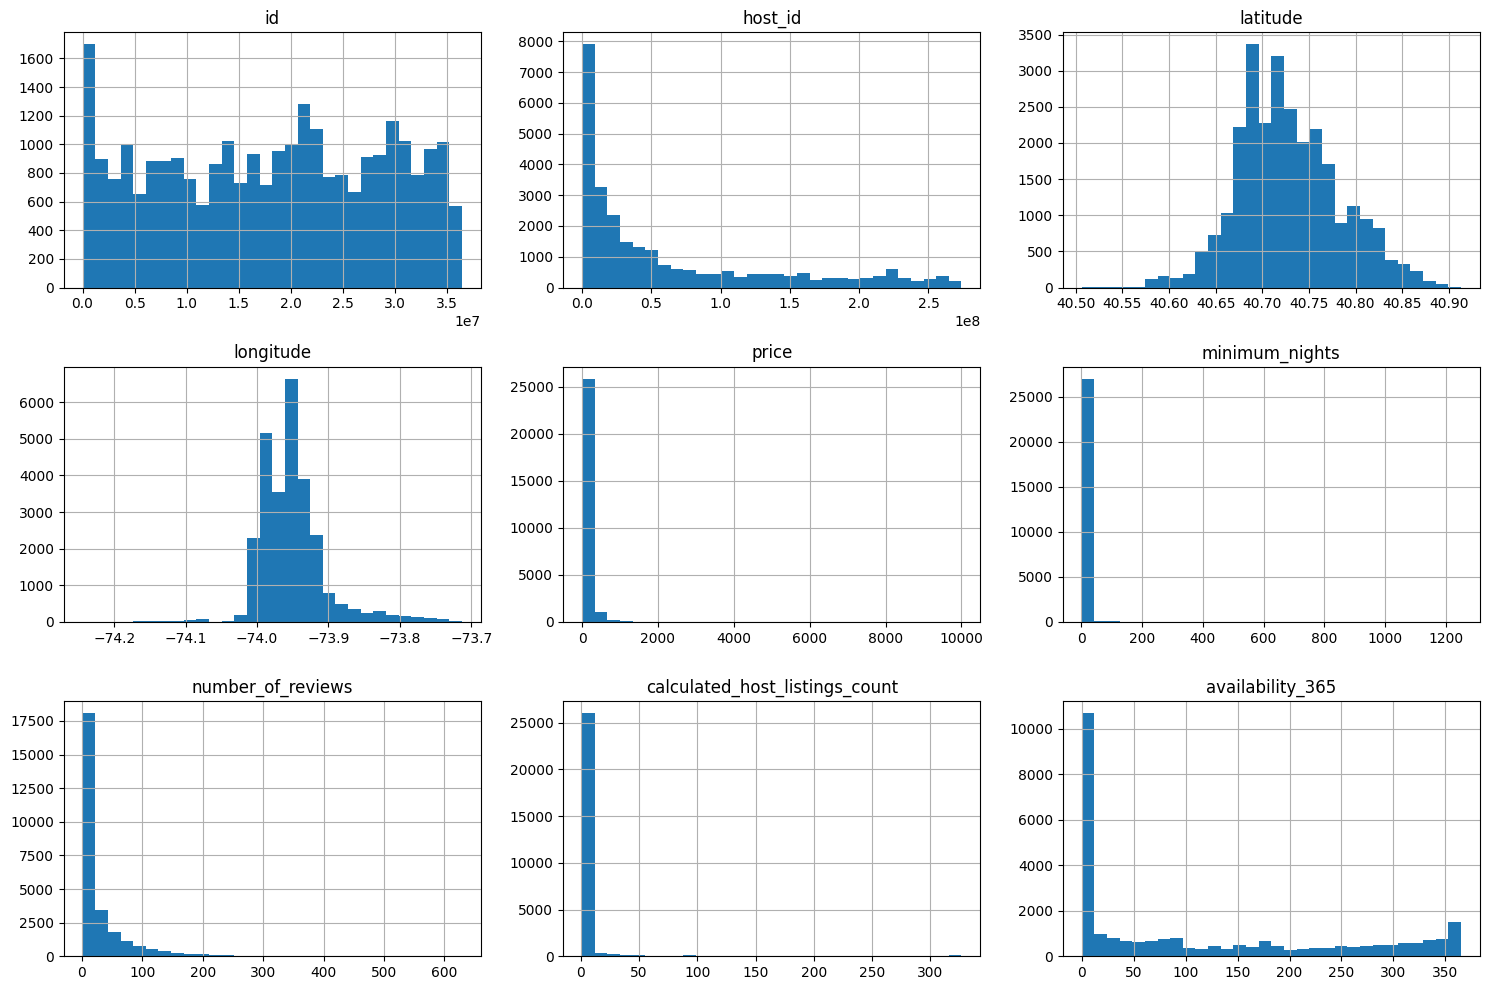

In [11]:
X_train.select_dtypes(include=["int64", "float64"]).hist(
    figsize=(15, 10),
    bins=30
)

plt.tight_layout()
plt.show()

Longitude and latitude appear to have clustered distributions with several peaks, suggesting that Airbnb listings are concentrated in particular geographic areas of New York City rather than being evenly distributed throughout the city.

The distribution of price is highly right-skewed. Most listings are relatively inexpensive, while a small number of listings have extremely high prices, indicating the presence of outliers.

The minimum_nights feature is strongly right-skewed, with most listings requiring only a small number of nights and a few listings requiring unusually long minimum stays.

The number_of_reviews feature is also right-skewed, suggesting that most listings receive relatively few reviews while a small number receive substantially more.

The calculated_host_listings_count feature is heavily right-skewed, indicating that most hosts own only a few listings while a small number of hosts manage many properties.

Availability_365 shows concentrations near both 0 and 365 days, suggesting that some listings are rarely available while others are available throughout most of the year.


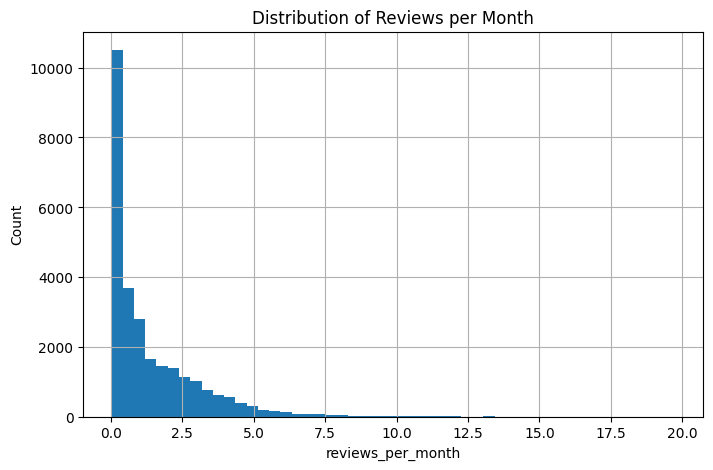

In [12]:
plt.figure(figsize=(8, 5))

y_train.hist(bins=50)

plt.xlabel("reviews_per_month")
plt.ylabel("Count")
plt.title("Distribution of Reviews per Month")

plt.show()

The distribution of reviews_per_month is highly right-skewed, which could even be concluded from the describe() summary since mean is 0.72 and median is 1.37, mean>median. Most Airbnb listings receive relatively few reviews per month, with the majority receiving fewer than 5 reviews. Only a small number of listings receive very large numbers of reviews, creating a long right tail in the distribution. This suggests that listing popularity is unevenly distributed across listings, with a few highly popular listings receiving substantially more reviews than the average listing. While most listings receive relatively few reviews per month, a small number receive exceptionally high numbers of reviews, with some listings receiving over 50 reviews per month. These observations may be considered outliers and could influence the model.

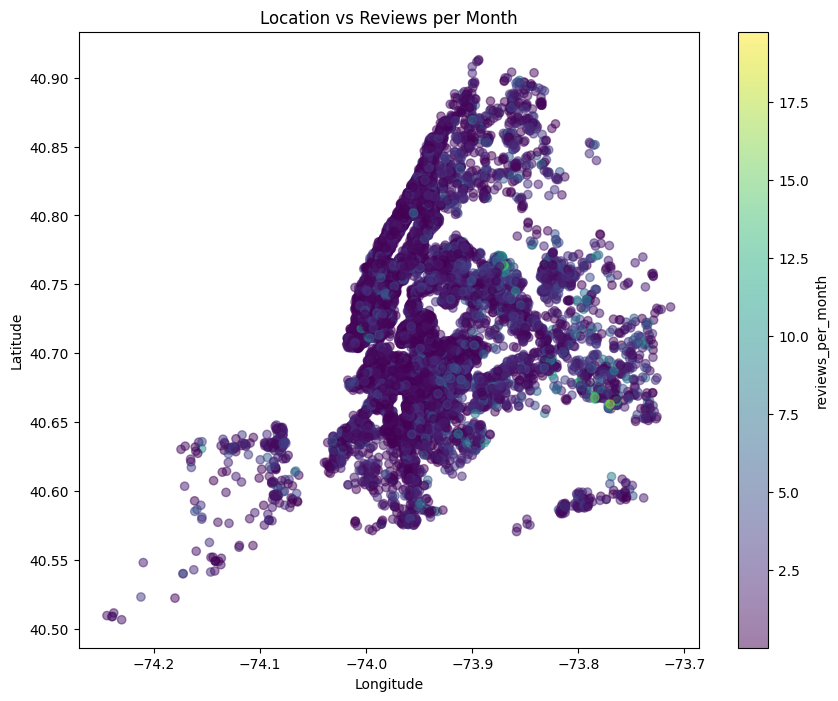

In [13]:
plt.figure(figsize=(10, 8))

plt.scatter(
    train_df["longitude"],
    train_df["latitude"],
    c=train_df["reviews_per_month"],
    alpha=0.5
)

plt.colorbar(label="reviews_per_month")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Location vs Reviews per Month")

plt.show()

The scatter plot clearly indicates that airbnb's are concetrated in several specific geographic locations of newyork city (beetween longtiude, -74.05 - -73.85 and latitude 40.65 to 40.85.), rather than being uniformly disturbuted. Most listings appear dark purple, indicating relatively low values of reviews_per_month, which is consistent with the strongly right-skewed distribution observed earlier. Although it is difficult to identify clear geographic patterns because most observations have similar colours, there appear to be some localized areas with higher review activity, suggesting that location may have some influence on listing popularity. The target is extrenely skewed making this plot extremely diffcult to intepret. 

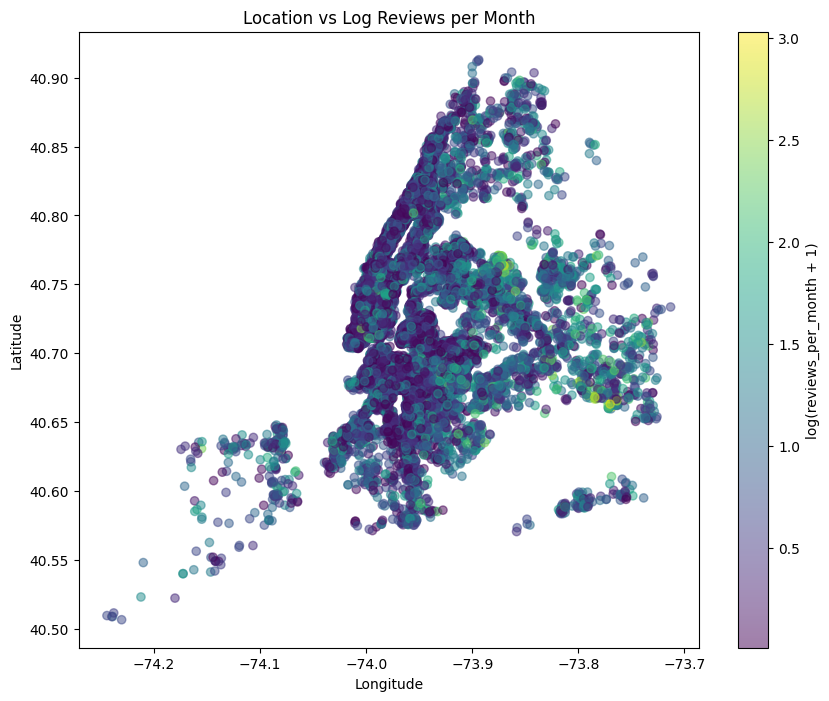

In [14]:
#suggested by chatgpt to do a log transformation for better intepration of results as compared to the last scatter plot, created above so that the larger values can be compressed and spread out the smaller values so difference in color is more observable for pattern observations
plt.figure(figsize=(10,8))

plt.scatter(
    train_df["longitude"],
    train_df["latitude"],
    c=np.log1p(train_df["reviews_per_month"]),
    alpha=0.5
)

plt.colorbar(label="log(reviews_per_month + 1)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Location vs Log Reviews per Month")
plt.show()

After applying a log transformation to reviews_per_month, the geographic patterns become easier to observe. Airbnb listings remain highly concentrated in several regions of New York City, particularly between approximately longitude -74.05 and -73.85 and latitude 40.65 and 40.85. Unlike the original plot, the transformed colour scale reveals greater variation in popularity across locations, suggesting that geographic location may have some influence on the number of reviews a listing receives. This indicates that latitude and longitude could be useful predictors in the model.

In [15]:
...

Ellipsis

In [16]:
...

Ellipsis

In [17]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 4. Feature engineering
<hr>
rubric={points:1}

<div class="alert alert-info">
    
**Your tasks:**

1. **Perform feature engineering**: Create new features that are relevant to the problem and use this updated feature set in the following exercises. You may need to iterate between **feature engineering** and **preprocessing** to refine your features and improve model performance.
   
</div>

<div class="alert alert-warning">
    
Solution_4
    
</div>

_Points:_ 1

In [18]:
X_train["log_price"] = np.log1p(X_train["price"])
X_test["log_price"] = np.log1p(X_test["price"])

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 5. Preprocessing and transformations
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Identify feature types**: Determine the different types of features in your dataset (e.g., numerical, categorical, ordinal, text) and specify the transformations you would apply to each type.

2. **Define a column transformer (if needed)**: Implement a `ColumnTransformer` to apply the appropriate preprocessing steps to each feature type.
 
</div>

<div class="alert alert-warning">
    
Solution_5
    
</div>

_Points:_ 10

In [19]:
drop_features = ["id", "name", "host_id", "host_name", "last_review"]

Dropping these feature because as they are all identifiers, they are unlikely to generalize well in a simple model. 

In [20]:
numeric_features = ["latitude","longitude","price","minimum_nights","number_of_reviews","calculated_host_listings_count", "availability_365", "log_price"]
categorical_features = [  "neighbourhood_group", "neighbourhood","room_type"]

In [21]:
numeric_transformer = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

In [22]:
categorical_transformer = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features),
        ("drop", "drop", drop_features)
    ]
)

In the above preprocessing, I have imputed both numerical and categorical features as that allows for a more robust pipeline however, it was not absolute neccessary since last_review was dropped which was the only feature with missing values. All numerical feature were scalled because magntiude of feature varried largely which could have introduced biases in the model, one hot encoder was used since we don't require ordinal encoding as they don't have any natural ordering. Ordinal encoding would incorrectly introduce a hierarchy between categories. The handle_unknwon arg

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 6. Baseline model
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. **Establish a baseline**: Use one of `scikit-learn`’s baseline models (e.g., `DummyClassifier` or `DummyRegressor`, depending on your task) and report the results. This will serve as a reference point for evaluating the performance of your more advanced models.

</div>

<div class="alert alert-warning">
    
Solution_6
    
</div>

_Points:_ 2

In [24]:
dummy = DummyRegressor(strategy="mean")
dummy_scores = pd.DataFrame(
    cross_validate(
        dummy,
        X_train,
        y_train,
        cv=5,
        scoring=["r2", "neg_root_mean_squared_error"],
        return_train_score=True
    )
)

dummy_scores["test_RMSE"] = -dummy_scores["test_neg_root_mean_squared_error"]
dummy_scores["train_RMSE"] = -dummy_scores["train_neg_root_mean_squared_error"]

dummy_scores[["train_r2", "test_r2", "train_RMSE", "test_RMSE"]].mean()


train_r2      0.000000
test_r2      -0.000058
train_RMSE    1.642409
test_RMSE     1.642393
dtype: float64

The DummyRegressor achieved a cross-validation R² score of approximately 0 on the training and validation folds, indicating that it performs no better than predicting the mean value of the target variable for all observations. The RMSE was approximately 1.64 reviews per month on both the training and validation folds. These results provide a baseline against which more sophisticated models can be compared. Any useful model should achieve a higher R² score and a lower RMSE than the DummyRegressor.

In [25]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 7. Linear models 
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Train a linear model**: Use a linear model as your first real attempt at solving the problem.

2. **Tune hyperparameters**: Perform hyperparameter tuning to explore different values of the model's complexity parameter. 

3. **Evaluate with cross-validation**: Report the cross-validation scores along with their standard deviation.

4. **Summarize findings**: Summarize your results, highlighting key observations from your experiments.

</div>

<div class="alert alert-warning">
    
Solution_7
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [26]:
ridge_pipe = make_pipeline(

    preprocessor,

    Ridge()

)

param_grid = {

    "ridge__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]

}

ridge_search = GridSearchCV(

    ridge_pipe,

    param_grid=param_grid,

    cv=5,

    scoring="r2",

    n_jobs = -1,

    return_train_score=True

)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_)

print("Best CV R2:", ridge_search.best_score_)

Best alpha: {'ridge__alpha': 10}
Best CV R2: 0.35874111052263835


In [27]:
best_ridge = ridge_search.best_estimator_

ridge_scores = pd.DataFrame(
    cross_validate(
        best_ridge,
        X_train,
        y_train,
        cv=5,
        scoring=["r2", "neg_root_mean_squared_error"],
        return_train_score=True
    )
)

ridge_scores["train_RMSE"] = -ridge_scores["train_neg_root_mean_squared_error"]
ridge_scores["test_RMSE"] = -ridge_scores["test_neg_root_mean_squared_error"]

ridge_scores[["train_r2", "test_r2", "train_RMSE", "test_RMSE"]].mean()

train_r2      0.370778
test_r2       0.358741
train_RMSE    1.302809
test_RMSE     1.315048
dtype: float64

In [28]:
ridge_model = best_ridge.named_steps["ridge"]

print("Intercept:", ridge_model.intercept_)
print("Number of coefficients:", len(ridge_model.coef_))
print("First 10 coefficients:", ridge_model.coef_[:10])

Intercept: 1.6257932795308396
Number of coefficients: 230
First 10 coefficients: [-0.12957337  0.24352856 -0.01296814 -0.13954425  0.86000505  0.00468127
  0.08592167  0.04537693  0.05003615 -0.34229793]


I have used ridge as my linear model because it can penalize the large co-efficents using the alpha hyperparamter. I tested alpha values from a range of 0.001 to 1000 because this covers very weak to very strong regulization. I used cross validation to choose the best alpha, so that there is no bias since if we had only use one validation set there would be, then evaluated the tuned Ridge model using R² and RMSE. 

The tuned Ridge model achieved a validation R² of about 0.359, meaning it explains around 36% of the variation in reviews_per_month. Its validation RMSE is about 1.315 reviews per month, which is better than the DummyRegressor baseline RMSE of about 1.64. The train and validation scores are also close, suggesting the model is not strongly overfitting. Overall, Ridge improves noticeably over the baseline but still leaves a large amount of variation unexplained.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 8. Different models
<hr>
rubric={points:12}

<div class="alert alert-info">
    
**Your tasks:**

1. **Experiment with additional models**: Train at least **three models** other than a linear model. Ensure that **at least one** of these models is a **tree-based ensemble model** (e.g., Random Forest, Gradient Boosting, or XGBoost).

2. **Compare and interpret results**: Summarize your findings in terms of **overfitting/underfitting** behavior and **fit/score times** for each model. Reflect on your results. Were you able to **outperform the linear model**?

</div>

<div class="alert alert-warning">
    
Solution_8
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

In [29]:
#KNN model: 

knn_pipe = make_pipeline(
    preprocessor,
    KNeighborsRegressor(n_neighbors=10)
)

In [30]:
#Decision Tree: 
tree_pipe = make_pipeline(
    preprocessor,
    DecisionTreeRegressor(
        max_depth=10,
        random_state=123
    )
)

In [31]:
#random forest: 
rf_pipe = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=123,
        n_jobs=-1
    )
)

In [32]:
#Helpfer function suggested by chatgpt to be more efficent:

def evaluate_model(model, X_train, y_train):

    scores = pd.DataFrame(
        cross_validate(
            model,
            X_train,
            y_train,
            cv=5,
            scoring=["r2", "neg_root_mean_squared_error"],
            return_train_score=True
        )
    )

    return {
        "train_r2": scores["train_r2"].mean(),
        "test_r2": scores["test_r2"].mean(),
        "train_RMSE": (-scores["train_neg_root_mean_squared_error"]).mean(),
        "test_RMSE": (-scores["test_neg_root_mean_squared_error"]).mean(),
        "fit_time": scores["fit_time"].mean()
    }

In [36]:
results = {}

results["Ridge"] = {
    "train_r2": 0.3708,
    "test_r2": 0.3587,
    "train_RMSE": 1.3028,
    "test_RMSE": 1.3150,
    "fit_time": None
}

results["KNN"] = evaluate_model(knn_pipe, X_train, y_train)
results["Decision Tree"] = evaluate_model(tree_pipe, X_train, y_train)
results["Random Forest"] = evaluate_model(rf_pipe, X_train, y_train)

pd.DataFrame(results).T


,train_r2,test_r2,train_RMSE,test_RMSE,fit_time
Ridge,0.370800,0.358700,1.302800,1.315000,NaN
KNN,0.512410,0.404610,1.146848,1.267096,0.032828
Decision Tree,0.619361,0.470527,1.013294,1.194934,0.133368
Random Forest,0.650665,0.540847,0.970730,1.112703,1.474418


Random Forest achieved the highest test R^2 score of approximately 0.54 and the lowest RMSE. This is likely because it can model complex nonlinear relationships and interactions between features such as neighbourhood, room type, price, and availability, whereas simpler models such as Ridge assume mostly linear relationships. The R^2 value indicates that approximately 54% of the variation in reviews_per_month can be explained by the model.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 9. Feature selection 
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. **Perform feature selection**: Attempt to select relevant features using methods such as `RFECV` or forward selection.

2. **Evaluate the impact** Compare the model performance before and after feature selection. Do the results improve with feature selection?

3. **Summarize findings** Summarize your observations and decide whether to **keep feature selection** in your pipeline.  If it improves results, retain it for the next exercises; otherwise, you may choose to omit it.
</div>

<div class="alert alert-warning">
    
Solution_9
    
</div>

_Points:_ 2

_Type your answer here, replacing this text._

In [41]:
rfecv_pipe = make_pipeline(
    preprocessor,
    RFECV(
        estimator=RandomForestRegressor(
            n_estimators=100,
            random_state=123,
            n_jobs=-1,
            max_depth=10
        ),
        step=10,
        cv=3,
        scoring="r2",
        n_jobs=-1
    )
)

rfecv_pipe.fit(X_train, y_train)

rfecv = rfecv_pipe.named_steps["rfecv"]

print("Number of selected features:", rfecv.n_features_)

Number of selected features: 20


In [42]:
rfecv_scores = pd.DataFrame(
    cross_validate(
        rfecv_pipe,
        X_train,
        y_train,
        cv=3,
        scoring=["r2", "neg_root_mean_squared_error"],
        return_train_score=True,
        n_jobs=-1
    )
)

rfecv_scores["train_RMSE"] = -rfecv_scores["train_neg_root_mean_squared_error"]
rfecv_scores["test_RMSE"] = -rfecv_scores["test_neg_root_mean_squared_error"]

rfecv_scores[
    ["train_r2", "test_r2", "train_RMSE", "test_RMSE"]
].mean()

train_r2      0.664550
test_r2       0.536195
train_RMSE    0.951241
test_RMSE     1.118464
dtype: float64

RFECV using a Random Forest estimator selected only 20 features from the original feature set. The resulting model achieved a test R² of approximately 0.54 and a test RMSE of approximately 1.12, which is very similar to the performance of the full Random Forest model. This suggests that many of the original features contributed little predictive information and that a much smaller subset of features was sufficient to achieve comparable performance.

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 10. Hyperparameter optimization
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Optimize hyperparameters**: Attempt to optimize hyperparameters for the models you have tried so far. In at least **one case**, tune **multiple hyperparameters** for a single model.

2. **Use suitable optimization methods**: You may use any of the following approaches for hyperparameter optimization:
   - [`GridSearchCV`](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)  
   - [`RandomizedSearchCV`](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)  
   - [Bayesian optimization with scikit-optimize](https://github.com/scikit-optimize/scikit-optimize)

3. **Summarize your results**: Report and compare the optimized results across models. Discuss whether hyperparameter optimization led to performance improvements.

</div>

<div class="alert alert-warning">
    
Solution_10
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [43]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "randomforestregressor__n_estimators": [50, 100, 200],
    "randomforestregressor__max_depth": [5, 10, 15, None],
    "randomforestregressor__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipe,
    param_grid,
    cv=3,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("Best CV score:")
print(grid_search.best_score_)

Best parameters:
{'randomforestregressor__max_depth': 15, 'randomforestregressor__min_samples_split': 2, 'randomforestregressor__n_estimators': 200}
Best CV score:
0.5404967803381168


I performed hyperparameter tuning on the Random Forest model using GridSearchCV with 3-fold cross-validation and R² as the evaluation metric.

The following hyperparameters were explored:

- n_estimators: [50, 100, 200]
- max_depth: [5, 10, 15, None]
- min_samples_split: [2, 5]

The best combination found was:

- n_estimators = 200
- max_depth = 15
- min_samples_split = 2

This configuration achieved a cross-validation R² score of approximately 0.5405.

Compared to the original Random Forest model, the improvement was very small. The untuned model achieved a test R² of approximately 0.5408, while the optimized model achieved a cross-validation R² of approximately 0.5405. This suggests that the original model was already close to optimal and that additional hyperparameter tuning provided little benefit.

Overall, Random Forest remained the best-performing model among all models tested, outperforming Ridge Regression, KNN, and Decision 

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 11. Interpretation and feature importances
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Interpret model feature importance**: Use one of the interpretation methods discussed in class (e.g., `shap`), or another suitable method of your choice, to examine the most important features of one of your **non-linear models**.

2. **Summarize insights**: Summarize your observations about which features contribute most to the model's predictions and how they influence the outcomes.

   
</div>

<div class="alert alert-warning">
    
Solution_11
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [44]:
best_rf = rf_pipe.fit(X_train, y_train)

In [45]:
feature_names = best_rf.named_steps["columntransformer"].get_feature_names_out()

In [46]:
importances = best_rf.named_steps["randomforestregressor"].feature_importances_

feat_imp = pd.DataFrame(

    {

        "feature": feature_names,

        "importance": importances

    }

)

feat_imp = feat_imp.sort_values(

    "importance",

    ascending=False

)

feat_imp.head(10)

,feature,importance
4,numeric__number_of_reviews,0.536446
3,numeric__minimum_nights,0.158386
6,numeric__availability_365,0.126492
1,numeric__longitude,0.045691
0,numeric__latitude,0.025571
2,numeric__price,0.010574
7,numeric__log_price,0.010569
5,numeric__calculated_host_listings_count,0.010445
70,categorical__neighbourhood_East Elmhurst,0.009838
190,categorical__neighbourhood_Springfield Gardens,0.004908


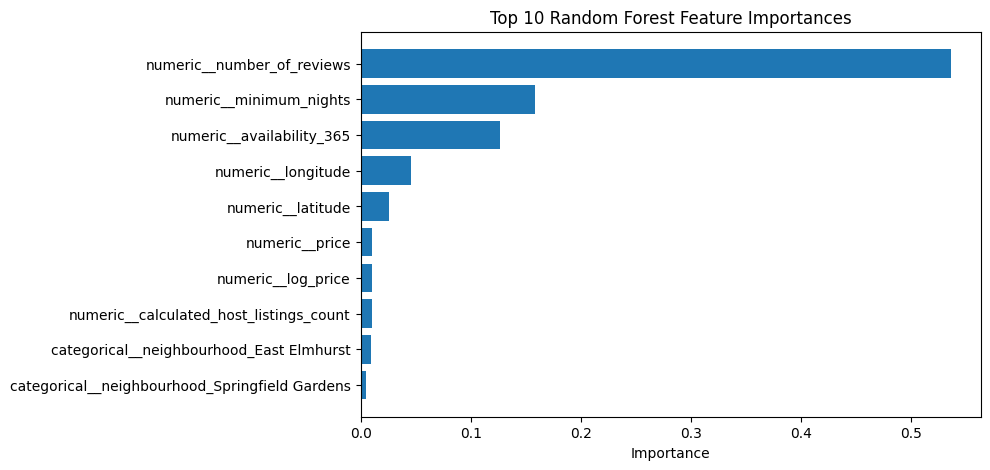

In [47]:

top10 = feat_imp.head(10)

plt.figure(figsize=(8,5))
plt.barh(top10["feature"], top10["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Top 10 Random Forest Feature Importances")
plt.show()

Feature importance was analyzed using the Random Forest model's built-in feature importance scores.

The most important features were:

1. number_of_reviews (importance ≈ 0.536)
2. minimum_nights (importance ≈ 0.158)
3. availability_365 (importance ≈ 0.126)
4. longitude (importance ≈ 0.046)
5. latitude (importance ≈ 0.026)

Other features such as price, log_price, calculated_host_listings_count, and individual neighbourhood indicators had substantially lower importance.

The results suggest that the number of reviews a listing has received is by far the strongest predictor of reviews_per_month. This is reasonable because listings that have accumulated many reviews are likely to continue receiving reviews in the future.

Minimum nights and availability_365 were also important predictors, indicating that booking restrictions and listing availability influence how frequently guests leave reviews.

Location-related features such as longitude and latitude contributed useful information, suggesting that geographical location affects listing popularity and review activity.

Overall, the model relies primarily on previous review activity, booking restrictions, availability, and location when predicting reviews_per_month.

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 12. Results on the test set
<hr>

rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Evaluate on the test set**: Apply your best-performing model to the test data and report the test scores.

2. **Compare and reflect**: Compare the **test scores** with the **validation scores** from previous experiments. Discuss the consistency between them. How much do you **trust your results**? Reflect on whether you might have encountered **optimization bias**.

3. **Explain individual predictions**: Select one or two examples from your test predictions and use an interpretation method (e.g., **SHAP force plots**) to explain these individual predictions.
</div>

<div class="alert alert-warning">
    
Solution_12
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [49]:
from sklearn.metrics import r2_score, root_mean_squared_error
import pandas as pd

best_model = grid_search.best_estimator_

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

test_r2 = r2_score(y_test, y_pred)
test_rmse = root_mean_squared_error(y_test, y_pred)

print("Test R²:", test_r2)
print("Test RMSE:", test_rmse)

Test R²: 0.5076967468129734
Test RMSE: 1.2389572040593477


In [50]:
predictions_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "error": y_test - y_pred
})

predictions_df.head(10)

,actual,predicted,error
17247,0.30,0.370319,-0.070319
9782,0.02,0.054260,-0.034260
593,0.21,0.468236,-0.258236
33216,1.81,1.223184,0.586816
460,0.79,1.241554,-0.451554
34852,0.63,1.924869,-1.294869
33795,1.61,1.119289,0.490711
28312,0.16,0.262120,-0.102120
37282,0.38,0.222632,0.157368
34044,0.10,0.311779,-0.211779


In [52]:
print(type(X_test_transformed))
print(X_test_transformed.dtype)

<class 'scipy.sparse._csr.csr_matrix'>
float64


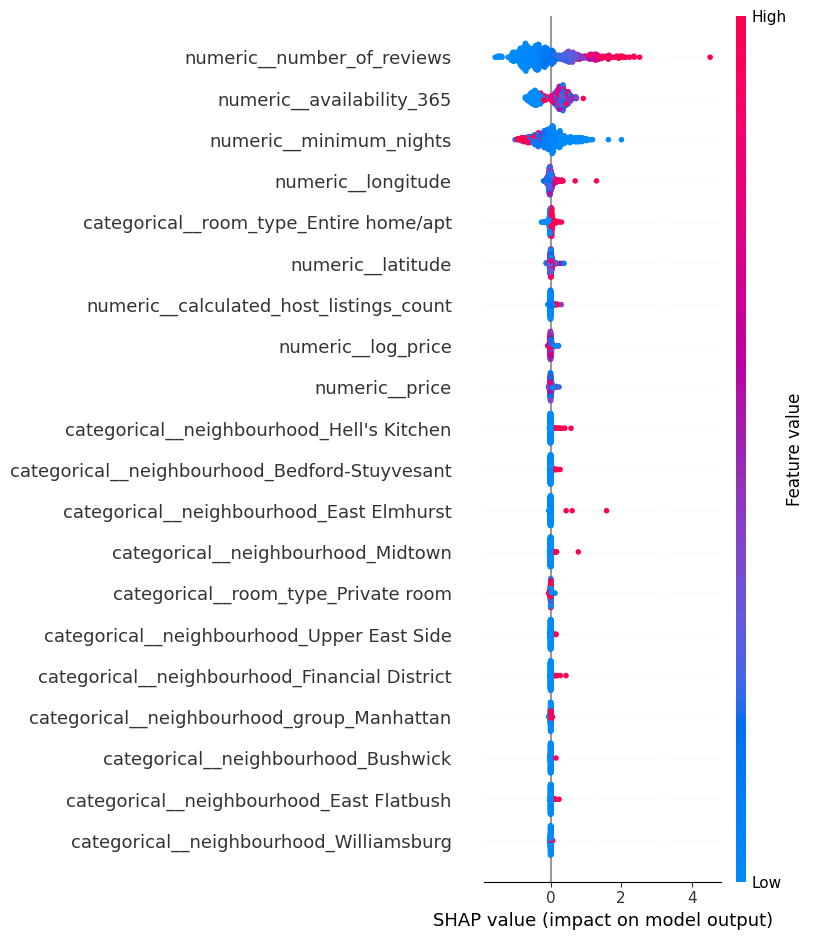

In [53]:
import shap

best_model = grid_search.best_estimator_
best_model.fit(X_train, y_train)

X_test_transformed = best_model.named_steps["columntransformer"].transform(X_test)
feature_names = best_model.named_steps["columntransformer"].get_feature_names_out()
rf_model = best_model.named_steps["randomforestregressor"]

X_test_sample = X_test_transformed[:500].toarray().astype(float)

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test_sample)

shap.summary_plot(
    shap_values,
    X_test_sample,
    feature_names=feature_names
)

The Random Forest model achieved a cross-validation R² of approximately 0.54 and a test R² of approximately 0.51. The similarity between these scores suggests that the model generalizes reasonably well to unseen data and is not severely overfitting. The test RMSE of approximately 1.24 is also close to the validation RMSE observed during model selection. Therefore, the final model appears reliable, although individual predictions can still contain substantial errors for certain listings.

SHAP analysis shows that the most important predictor of reviews per month is the total number of reviews, followed by availability throughout the year and minimum nights required. Listings with many existing reviews and greater availability generally increase the predicted number of monthly reviews, while higher minimum night requirements tend to reduce predicted review activity. Geographic location (latitude and longitude) also contributes to predictions, indicating that some neighbourhoods attract more guest activity than others. Overall, historical popularity, booking flexibility, and location appear to be the strongest drivers of Airbnb review frequency.

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

In [ ]:
...

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 13. Summary of results
<hr>
rubric={points:12}

Imagine you are preparing to present the summary of your results to your boss and co-workers.

<div class="alert alert-info">
    
**Your tasks:**

1. **Summarize key results**: Create a clear and concise table highlighting your most important results (e.g., models compared, validation/test scores, key observations).

2. **Write concluding remarks**: Summarize your main takeaways from the project, including what worked well and what did not.

3. **Propose future improvements**: Discuss ideas or approaches you did not try but that could potentially improve **performance** or **interpretability**.

4. **Report final results**: Report your **final test score** and the **metric** you used.

</div>


<div class="alert alert-warning">
    
Solution_13
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

The Random Forest model achieved the best overall performance (R^2 of 0.541 and RMSE of 1.113) and was selected as the final model . Hyperparameter tuning further improved the model, with the best parameters being n_estimators=200, max_depth=15, and min_samples_split=2.

The project demonstrated that non-linear models significantly outperformed linear models for predicting Airbnb reviews per month. Exploratory data analysis revealed a highly right-skewed target variable and strong geographical patterns. Feature engineering and preprocessing helped improve model performance, while Random Forest was able to capture complex relationships between variables better than Ridge Regression, KNN, or Decision Trees.

Feature importance and SHAP analysis showed that the most influential variables were the number of reviews, availability throughout the year, minimum nights, and location-related features.

Potential improvements include:

* Creating additional location-based features using clustering techniques.
* Extracting useful information from textual features such as listing names.
* Performing more extensive hyperparameter tuning.
* Testing more advanced ensemble methods such as Gradient Boosting or XGBoost.
* Applying target transformations to further address the skewness of the response variable.

The final tuned Random Forest model achieved:

* Test R²: 0.508
* Test RMSE: 1.239

<!-- END QUESTION -->

<br><br>

<br><br>

<!-- BEGIN QUESTION -->

## 14. Your takeaway
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

What is your biggest takeaway from the supervised machine learning material we have learned so far? Please write thoughtful answers.  

</div>

My biggest takeaway from this course is that machine learning involves much more than simply choosing a model. Data preprocessing, feature engineering, evaluation metrics, and proper validation often have a larger impact on performance than the choice of algorithm itself. I also learned the importance of using cross-validation and test sets to obtain reliable estimates of model performance and avoid overfitting. Finally, interpretation tools such as feature importance and SHAP values help explain how models make predictions, making machine learning models more understandable and trustworthy.

<div class="alert alert-warning">
    
Solution_14
    
</div>

_Points:_ 2

<!-- END QUESTION -->

<br><br>

Before submitting your assignment, please make sure you have followed all the instructions in the Instructions section at the top.

Here is a quick checklist before submitting:

- [ ] Restart the kernel and run all cells.
- [ ] `hw5.ipynb` runs without errors and contains all outputs.
- [ ] Save `hw5.ipynb` in JupyterLab.
- [ ] Return to the PrairieLearn question page and click **Save only** to check the rendered notebook preview.
- [ ] When the preview looks correct, click **Save & Grade**.
- [ ] If you are working in a group, confirm your PrairieLearn group membership is correct.
- [ ] Review the [CPSC 330 homework instructions](https://ubc-cs.github.io/cpsc330-2026S1/docs/homework-instructions/) for details on the grading process.


This was a tricky one but you did it 👏👏!  

![](img/eva-well-done.png)